# QMSS5074GR: Projects in Advanced Machine Learning
## Project 1: World Happiness Classification

---

### Group Information

Fill this in before you submit.

**Group number:** 5

| Full Name | UNI |
|-----------|-----|
| Yingqi Huan | YH3755 |
| Jiayi Zhou  | JZ4216 |

**Public GitHub repository URL:** https://github.com/kikiyqhuan/QMSS5074GR-Projects-in-Advanced-Machine-Learning.git

## How to Complete and Submit This Project

**Due: Monday, October 19, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_1.ipynb`.

### 1. Get started

Everything you need comes in the project folder. No separate downloads are needed:

```
Fall2026_QMSS5074GR_Project_1/
├── Project_1.ipynb
└── data/
    ├── WHR_2023.csv
    └── newcountryvars.csv
```

1. Unzip the folder and open `Project_1.ipynb`.
2. Keep the `data` folder next to the notebook and don't rename any files. The code reads the data from `data/WHR_2023.csv` and `data/newcountryvars.csv`.
3. Run the first code cell in Section 0 to install the required packages.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Kernel → Restart & Run All**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible.
- Fill in the **Group Information** cell at the top, including your GitHub link.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 1 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_1` folder, with the `data` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_1/
    ├── Project_1.ipynb
    └── data/
        ├── WHR_2023.csv
        └── newcountryvars.csv
```

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart & Run All finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` and the `data` folder are in `Project_1/` in your public group repository

## About the Project

### What this project is about

Why are people in some countries happier than in others? Every year, the **World Happiness Report** surveys people around the world (through the Gallup World Poll) and asks them to rate their current life on a ladder from **0 (worst possible life)** to **10 (best possible life)**. A country's happiness score is the average of these answers.

In this project, you will build models that **predict how happy a country is from its economic, social, and development indicators**, and then look inside those models to see which factors matter most. Along the way, you will practice the full machine learning workflow: merging datasets, exploring data, engineering features, building a preprocessing pipeline, training and tuning classical models, training a neural network, and explaining predictions with SHAP.

### The prediction task

This is a **multi-class classification** problem. In Section 0, the numeric `happiness_score` is split into **five equal-sized groups** (quintiles) of about 27 countries each:

**Very Low → Low → Average → High → Very High**

Your models predict which group each country belongs to. With only **137 countries** (95 for training, 42 for testing), this is a small dataset, so keep that in mind when you interpret your results.

---

### The data

You will work with two files, both in the `data` folder.

#### 1. `WHR_2023.csv`: World Happiness Report 2023 (137 countries)

| Column | What it means |
|--------|---------------|
| `country` | Country name (used to merge with the second file) |
| `region` | World region (10 regions, e.g., *Western Europe*, *Sub-Saharan Africa*) |
| `happiness_score` | Average life rating on the 0–10 ladder, from surveys in 2020–2022. **Used only to create the target, not as a feature.** |
| `gdp_per_capita` | Contribution of economic output per person |
| `social_support` | Contribution of having someone to count on in times of trouble |
| `healthy_life_expectancy` | Contribution of the number of years people live in good health |
| `freedom_to_make_life_choices` | Contribution of people's satisfaction with their freedom to choose what to do with their lives |
| `generosity` | Contribution of donating to charity (adjusted for income) |
| `perceptions_of_corruption` | Contribution of how widespread people think corruption is in government and business |

> **Important:** The six factor columns are **not** raw measurements. The World Happiness Report estimates how much each factor adds to a country's happiness score compared with *"Dystopia"*, an imaginary country with the world's lowest value of every factor. They are measured in **happiness-score points**. For example, Finland's `healthy_life_expectancy` is 0.535: health adds about half a point to Finland's score. It does *not* mean a life expectancy of 0.535 years.

#### 2. `newcountryvars.csv`: Country development indicators (174 countries)

| Column | What it means |
|--------|---------------|
| `country_name` | Country name (used to merge with the first file) |
| `population` | Total population |
| `population_below_poverty_line` | Percentage of people living below the national poverty line |
| `hdi` | Human Development Index (0–1): the UN's summary measure of health, education, and income |
| `life_expectancy` | Life expectancy at birth, in years |
| `expected_years_of_schooling` | Years of schooling a child starting school can expect to receive |
| `mean_years_of_schooling` | Average years of schooling completed by adults aged 25 and older |
| `gni` | Gross National Income per person, in international dollars adjusted for cost of living (PPP) |

These indicators come from roughly **2015–2017**, a few years earlier than the happiness surveys, and some values are missing.

#### Combining the two files

In Section 0, you will merge the second file into the first using `country` and `country_name`. Not every country appears in both files, and some countries are spelled differently, so check the merge carefully.

---

## 0. Loading Datasets

In this section, we load the two datasets described above, `WHR_2023.csv` and `newcountryvars.csv`, create the target variable, split the data into training and test sets, and merge in the extra country indicators.

**Objectives of this stage:**

- Import the datasets into the notebook environment
- Inspect their structure and contents
- Verify column names and data types
- Identify potential inconsistencies before merging

> Careful dataset inspection at this stage prevents downstream errors and ensures a clean modeling pipeline.

In [1]:
# Install the packages used in this project (quick if they are already installed)
%pip install -q pandas numpy scikit-learn matplotlib tensorflow shap

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Make sure the data folder is next to the notebook before loading anything.
# If it is missing (for example, in a fresh Google Colab runtime), download the two CSV files
# from our public GitHub repository into data/, so the cells below can read data/WHR_2023.csv.
import os
import urllib.request

DATA_URL = ("https://raw.githubusercontent.com/kikiyqhuan/"
            "QMSS5074GR-Projects-in-Advanced-Machine-Learning/main/Project_1/data/")
os.makedirs("data", exist_ok=True)
for file_name in ["WHR_2023.csv", "newcountryvars.csv"]:
    path = os.path.join("data", file_name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(DATA_URL + file_name, path)
        print("downloaded", path)
    else:
        print("found", path)

found data/WHR_2023.csv
found data/newcountryvars.csv


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset
whr_df = pd.read_csv('data/WHR_2023.csv')
print("WHR_2023 shape:", whr_df.shape)

# Inspect the first few rows to understand the structure
whr_df

WHR_2023 shape: (137, 9)


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption
0,Finland,Western Europe,7.804,1.888,1.585,0.535,0.772,0.126,0.535
1,Denmark,Western Europe,7.586,1.949,1.548,0.537,0.734,0.208,0.525
2,Iceland,Western Europe,7.530,1.926,1.620,0.559,0.738,0.250,0.187
3,Israel,Middle East and North Africa,7.473,1.833,1.521,0.577,0.569,0.124,0.158
4,Netherlands,Western Europe,7.403,1.942,1.488,0.545,0.672,0.251,0.394
...,...,...,...,...,...,...,...,...,...
132,Congo (Kinshasa),Sub-Saharan Africa,3.207,0.531,0.784,0.105,0.375,0.183,0.068
133,Zimbabwe,Sub-Saharan Africa,3.204,0.758,0.881,0.069,0.363,0.112,0.117
134,Sierra Leone,Sub-Saharan Africa,3.138,0.670,0.540,0.092,0.371,0.193,0.051
135,Lebanon,Middle East and North Africa,2.392,1.417,0.476,0.398,0.123,0.061,0.027


In [4]:
# Convert the regression target ('happiness_score') into classification labels
# We'll use quintiles to create 5 happiness categories: Very Low, Low, Average, High, Very High

# Define quintiles
whr_df['happiness_category'] = pd.qcut(whr_df['happiness_score'],
                                       q=5,
                                       labels=['Very Low', 'Low','Average', 'High', 'Very High'])

# Select features and target
X = whr_df.drop(columns=['happiness_score', 'happiness_category'])
y = whr_df['happiness_category']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Convert y_train and y_test to numerical labels
y_train_labels = y_train.astype('category').cat.codes
y_test_labels = y_test.astype('category').cat.codes

### Conceptual Question

In the next cell, briefly explain the following:

1. What does `y_train.astype('category').cat.codes` do?
2. What is the difference between `y_train_labels` and `y_train`?

Keep your explanation clear and concise.

1. `y_train.astype('category').cat.codes` converts `y_train` to categorical type and returns an integer code for each category. The codes range from 0 (Very Low) to 4 (Very High).
2. `y_train` contains the original happiness category labels, while `y_train_labels` contains their integer codes. They represent the same target values in different formats.

### Add New Data

In [5]:
# Country development indicators to merge
countrydata=pd.read_csv("data/newcountryvars.csv")
print("newcountryvars shape:", countrydata.shape)

countrydata.head()

newcountryvars shape: (174, 8)


,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,India,1339180127,21.9,0.623559,68.322,11.696590,6.298834,5663.474799
1,Nigeria,190886311,70.0,0.527105,53.057,9.970482,6.000000,5442.901264
2,Mexico,129163276,46.2,0.761683,76.972,13.299090,8.554985,16383.106680
3,Pakistan,197015955,29.5,0.550354,66.365,8.106910,5.089460,5031.173074
4,Bangladesh,164669751,31.5,0.578824,71.985,10.178706,5.241577,3341.490722


In [6]:
# Compare country names in the two files and list the names that do not match
whr_names = set(X_train["country"]).union(set(X_test["country"]))
new_names = set(countrydata["country_name"])
only_whr = sorted(whr_names - new_names)
only_new = sorted(new_names - whr_names)
print("WHR names missing from newcountryvars:", len(only_whr))
print(only_whr)
print("newcountryvars names missing from WHR:", len(only_new))
print("duplicate country_name:", countrydata["country_name"].duplicated().sum())

# Search the second file for spellings that may correspond to the unmatched names
needles = ["congo", "czech", "hong", "macedon", "palest", "taiwan", "turk", "viet"]
print("possible matches:")
for name in sorted(new_names):
    if any(needle in name.lower() for needle in needles):
        print(" ", name) # There is no Taiwan/Taiwan Province of China

WHR names missing from newcountryvars: 9
['Congo (Brazzaville)', 'Congo (Kinshasa)', 'Czechia', 'Hong Kong S.A.R. of China', 'North Macedonia', 'State of Palestine', 'Taiwan Province of China', 'Turkiye', 'Vietnam']
newcountryvars names missing from WHR: 46
duplicate country_name: 0
possible matches:
  Congo
  Czech Republic
  Democratic Republic of the Congo
  Hong Kong
  Macedonia
  Palestine
  Turkey
  Turkmenistan
  VietNam


In [7]:
# Merge in new data to X_train and X_test by taking "country" from first table and "country_name" from 2nd table.
# Also check which countries are common in both the datasets, and which type of merge will you perform for the best results.
# Hint: Look at the 'how' parameter of the pandas merge function.
# Note: Your merge must keep every row of X_train and X_test so they stay aligned with y_train and y_test.
# Some country names differ between the two files; you may optionally harmonize them before merging.

# Map 8 differently spelled WHR names to the names used in newcountryvars
# Taiwan has no row in the second file, so it is left out of the map
name_map = {
    "Congo (Brazzaville)": "Congo",
    "Congo (Kinshasa)": "Democratic Republic of the Congo",
    "Czechia": "Czech Republic",
    "Hong Kong S.A.R. of China": "Hong Kong",
    "North Macedonia": "Macedonia",
    "State of Palestine": "Palestine",
    "Turkiye": "Turkey",
    "Vietnam": "VietNam",
}

# Keep the original country column and store the corrected name in country_key
X_train = X_train.copy()
X_test = X_test.copy()
X_train["country_key"] = X_train["country"].replace(name_map)
X_test["country_key"] = X_test["country"].replace(name_map)

# Merge development indicators into the training and test sets, keeping every left-hand row
X_train = X_train.merge(countrydata, left_on="country_key", right_on="country_name", how="left")
X_test = X_test.merge(countrydata, left_on="country_key", right_on="country_name", how="left")

# Check that the row counts still match the labels, then print any country that did not match
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
print("train rows still unmatched:", X_train.loc[X_train["country_name"].isna(), "country"].tolist())
print("test rows still unmatched:", X_test.loc[X_test["country_name"].isna(), "country"].tolist())

X_train = X_train.drop(columns=["country_key"])
X_test = X_test.drop(columns=["country_key"])

train rows still unmatched: ['Taiwan Province of China']
test rows still unmatched: []


In [8]:
X_train.head(1)

,country,region,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,Madagascar,Sub-Saharan Africa,0.632,0.779,0.178,0.187,0.177,0.134,Madagascar,25570895.0,70.7,0.512149,65.515,10.34614,6.145955,1319.699397


---

## 1. Exploratory Data Analysis and Visualization (EDAV)

In [9]:
print(X_train.dtypes)

country                              str
region                               str
gdp_per_capita                   float64
social_support                   float64
healthy_life_expectancy          float64
freedom_to_make_life_choices     float64
generosity                       float64
perceptions_of_corruption        float64
country_name                         str
population                       float64
population_below_poverty_line    float64
hdi                              float64
life_expectancy                  float64
expected_years_of_schooling      float64
mean_years_of_schooling          float64
gni                              float64
dtype: object


### Describe What You Observe

The merged training data contain thirteen numeric indicators and three text columns. Only `region` is retained as a categorical predictor; the two country-name columns serve as identifiers. Missing entries reflect incomplete source indicators and one unmatched country.

The six WHR factors are contributions in happiness-score points. Development-file `life_expectancy`, by contrast, is measured in years.


### Missing Values Analysis

Compute the number and percentage of missing values for each column and present the results in a clear summary table.

In [10]:
# Count missing values and their percentage for every column of the training set, sorted from most to least missing
missing_summary = pd.DataFrame({
    "n_missing": X_train.isna().sum(),
    "pct_missing": (X_train.isna().mean() * 100).round(2),
})
missing_summary = missing_summary.sort_values(
    "pct_missing", ascending=False
)
missing_summary

,n_missing,pct_missing
population_below_poverty_line,11,11.58
life_expectancy,2,2.11
mean_years_of_schooling,2,2.11
expected_years_of_schooling,2,2.11
gni,2,2.11
population,1,1.05
hdi,1,1.05
country_name,1,1.05
perceptions_of_corruption,0,0.00
generosity,0,0.00


### Distribution of Key Numerical Features

Select relevant numerical features and plot their histograms. Choose features that may influence the target variable, and briefly comment on notable patterns, skewness, or outliers.

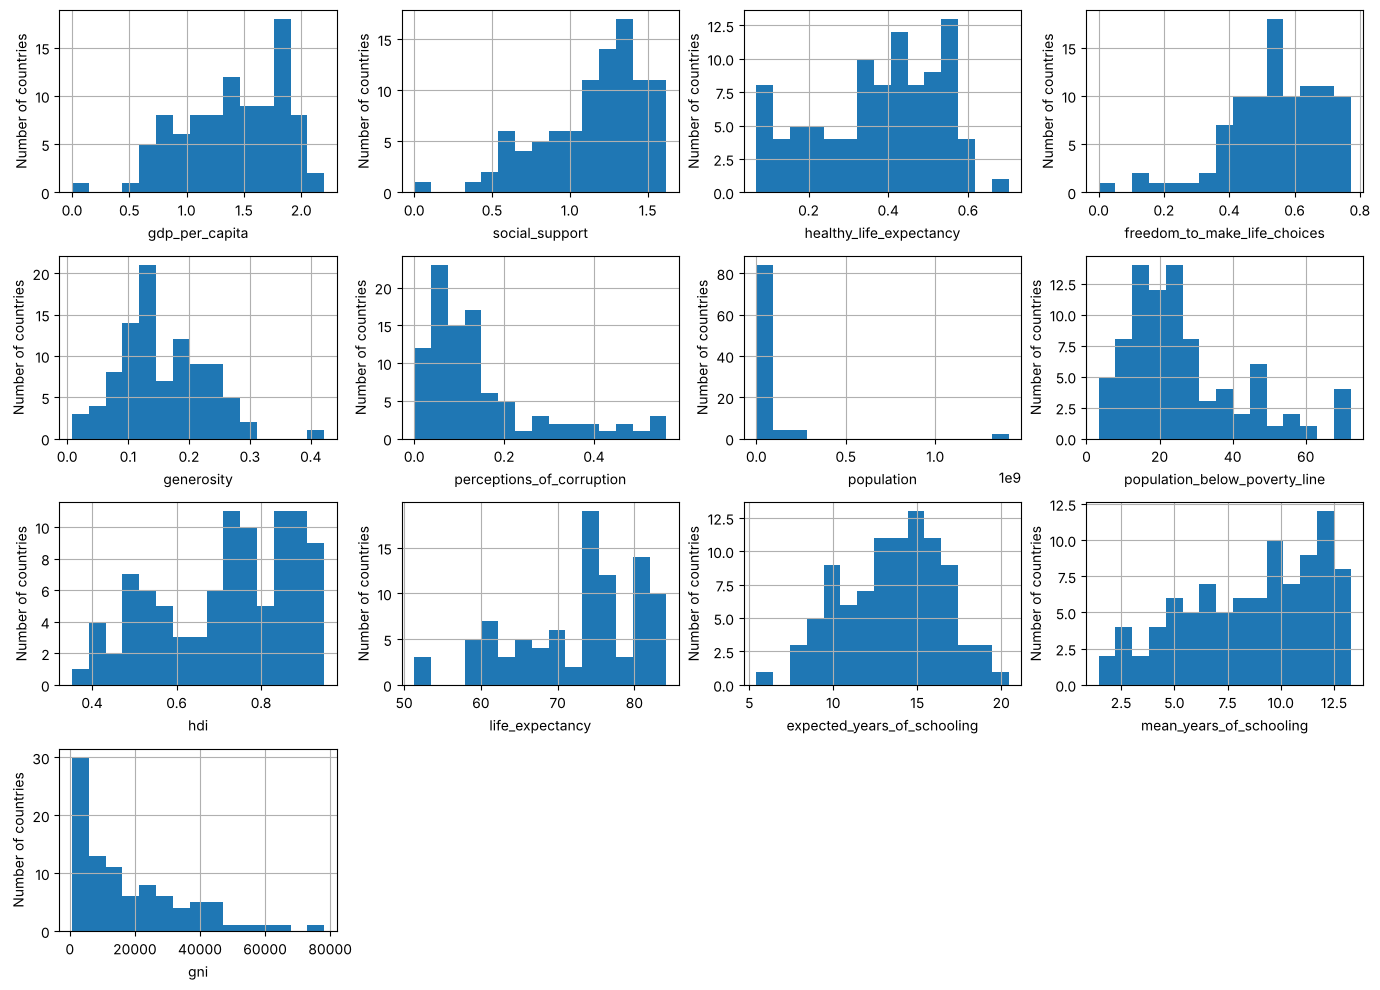

,count,missing,mean,std,min,50%,max,skew
gdp_per_capita,95.0,0,1.41,4.500000e-01,0.00,1.46,2.200000e+00,-0.55
social_support,95.0,0,1.16,3.300000e-01,0.00,1.23,1.620000e+00,-0.95
healthy_life_expectancy,95.0,0,0.37,1.600000e-01,0.07,0.40,7.000000e-01,-0.37
freedom_to_make_life_choices,95.0,0,0.54,1.500000e-01,0.00,0.55,7.700000e-01,-0.97
generosity,95.0,0,0.16,7.000000e-02,0.01,0.14,4.200000e-01,0.56
perceptions_of_corruption,95.0,0,0.15,1.300000e-01,0.00,0.10,5.600000e-01,1.60
population,94.0,1,59843364.34,2.005469e+08,335025.00,14283871.50,1.409517e+09,6.21
population_below_poverty_line,84.0,11,26.32,1.624000e+01,3.30,22.00,7.230000e+01,1.15
hdi,94.0,1,0.72,1.600000e-01,0.35,0.75,9.500000e-01,-0.50
life_expectancy,93.0,2,72.64,8.160000e+00,51.32,74.60,8.416000e+01,-0.69


In [11]:
# Plot histograms of every numeric training column
import matplotlib.pyplot as plt

hist_cols = [
    "gdp_per_capita", "social_support", "healthy_life_expectancy",
    "freedom_to_make_life_choices", "generosity", "perceptions_of_corruption",
    "population", "population_below_poverty_line", "hdi", "life_expectancy",
    "expected_years_of_schooling", "mean_years_of_schooling", "gni",
]

axes = X_train[hist_cols].hist(figsize=(14, 10), bins=15)
for ax in axes.ravel():
    if ax.get_title():
        ax.set_xlabel(ax.get_title())
        ax.set_ylabel("Number of countries")
        ax.set_title("")
plt.tight_layout()
plt.show()

summary = X_train[hist_cols].describe().T
summary["missing"] = X_train[hist_cols].isna().sum()
summary["skew"] = X_train[hist_cols].skew()
summary = summary[["count", "missing", "mean", "std", "min", "50%", "max", "skew"]]
summary.round(2)

The training set has 95 countries and 13 numeric columns. The six World Happiness factors are contributions on a small scale: `gdp_per_capita` runs from 0 to 2.20 (mean 1.41, median 1.46, SD 0.45), and the other five factors all lie between 0 and about 1.6. The merged indicators use very different units. `population` has a mean of about 59.8 million but a median of only 14.3 million (SD about 201 million); `gni` has a mean of about 18,100 but a median of about 12,400 (SD about 17,000). `population_below_poverty_line` averages 26% (median 22%, range 3% to 72%). `life_expectancy` averages 73 years (median 75, range 51 to 84), and `hdi` averages 0.72 (median 0.75, range 0.35 to 0.95). `mean_years_of_schooling` averages 8.6 years, while expected years average 13.6. `population` (skew 6.21), `perceptions_of_corruption` (1.60), `gni` (1.24), and `population_below_poverty_line` (1.15) are right-skewed, so their means sit above their medians. `social_support`, `freedom_to_make_life_choices`, `life_expectancy`, `hdi`, `gdp_per_capita`, and both schooling measures are mildly left-skewed.

### Distribution of Categorical Variables

Plot the distribution of relevant categorical variables using appropriate visualizations (e.g., count plots or bar charts). Briefly comment on class imbalance or notable patterns.

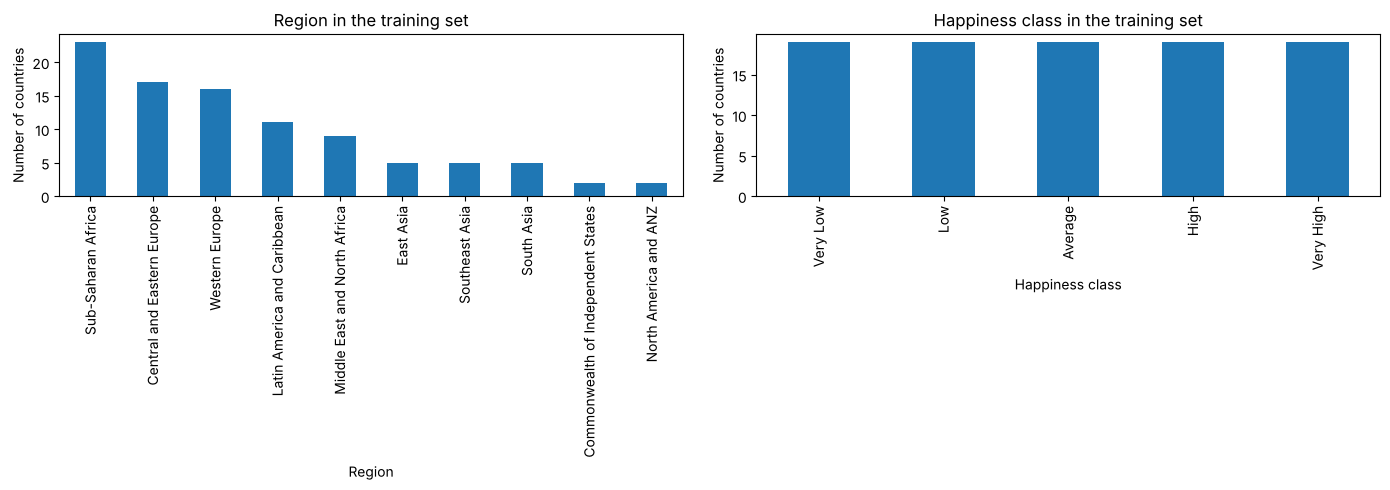

Region
                                    count  percent
region                                            
Sub-Saharan Africa                     23   24.211
Central and Eastern Europe             17   17.895
Western Europe                         16   16.842
Latin America and Caribbean            11   11.579
Middle East and North Africa            9    9.474
East Asia                               5    5.263
Southeast Asia                          5    5.263
South Asia                              5    5.263
Commonwealth of Independent States      2    2.105
North America and ANZ                   2    2.105
Happiness class
                    count  percent
happiness_category                
Very Low               19     20.0
Low                    19     20.0
Average                19     20.0
High                   19     20.0
Very High              19     20.0


In [12]:
# Plot region and the happiness class
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

region_counts = X_train["region"].value_counts()
region_counts.plot(kind="bar", ax=axes[0])
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Number of countries")
axes[0].set_title("Region in the training set")

class_order = ["Very Low", "Low", "Average", "High", "Very High"]
class_counts = y_train.astype(str).value_counts().reindex(class_order)
class_counts.plot(kind="bar", ax=axes[1])
axes[1].set_xlabel("Happiness class")
axes[1].set_ylabel("Number of countries")
axes[1].set_title("Happiness class in the training set")

plt.tight_layout()
plt.show()

region_table = pd.DataFrame({
    "count": region_counts,
    "percent": (region_counts / len(X_train) * 100).round(3),
})
class_table = pd.DataFrame({
    "count": class_counts,
    "percent": (class_counts / len(y_train) * 100).round(3),
})
print("Region")
print(region_table)
print("Happiness class")
print(class_table)

Each training class contains 19 countries. Region coverage is much less balanced: Sub-Saharan Africa contributes 23 observations, whereas North America and ANZ and the Commonwealth of Independent States each contribute two. No target-class reweighting is needed; region-specific comparisons remain limited by these small counts.

### Feature Correlation Analysis

Analyze the relationships between numerical features using correlation coefficients. Compute and visualize:

- **Pearson correlation** — linear relationships
- **Spearman correlation** — monotonic relationships
- **Kendall correlation** — rank-based relationships

Use correlation matrices and heatmaps where appropriate. Briefly interpret strong positive or negative correlations and discuss potential multicollinearity.

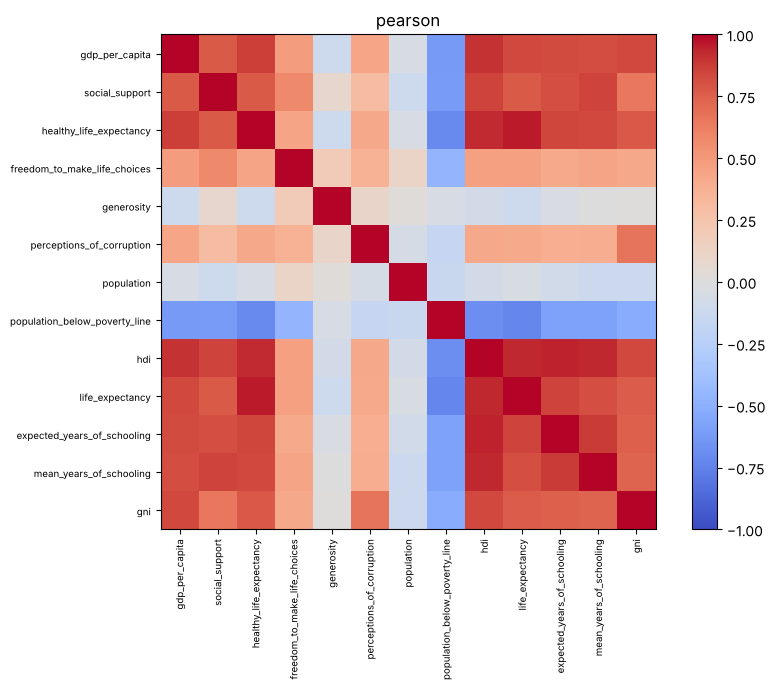

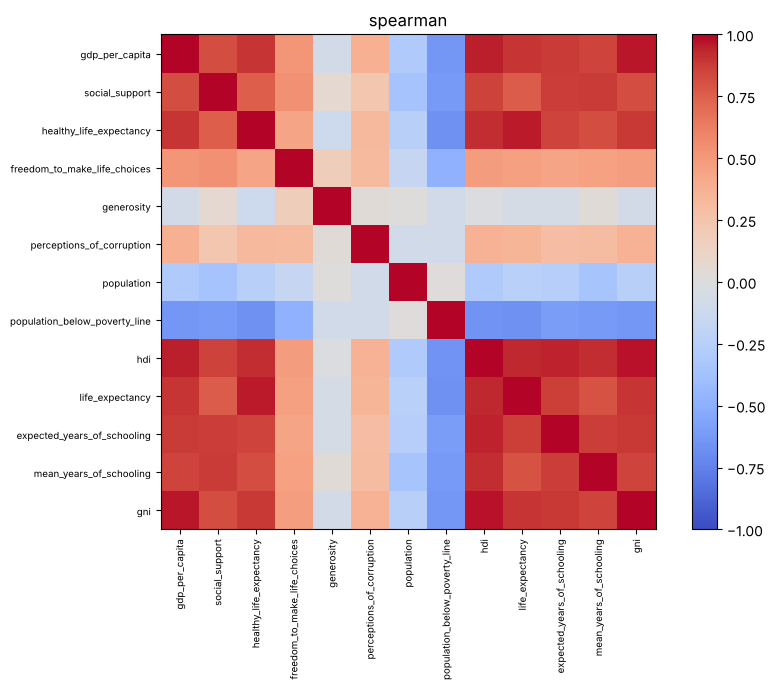

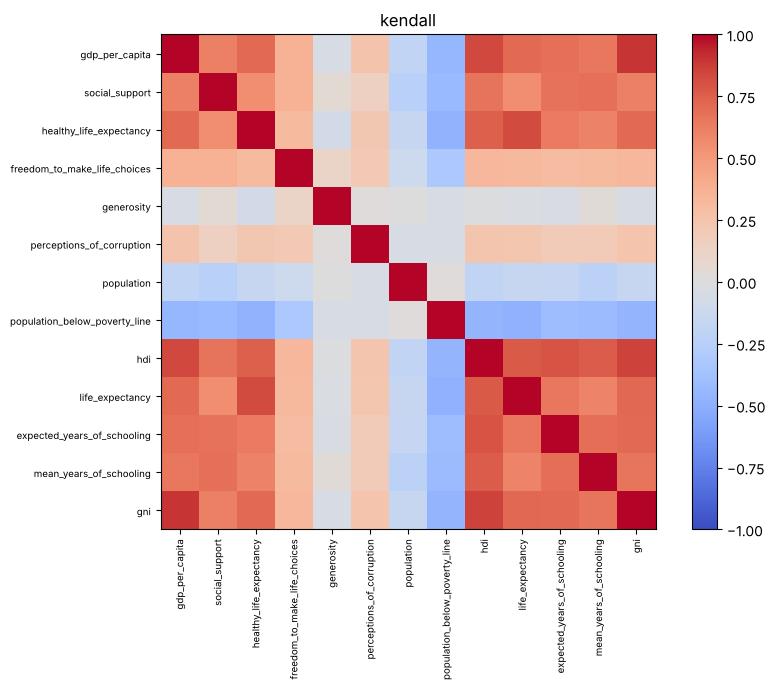

,feature_1,feature_2,pearson,spearman,kendall
14,healthy_life_expectancy,life_expectancy,0.958,0.955,0.820
20,hdi,expected_years_of_schooling,0.938,0.942,0.793
21,hdi,mean_years_of_schooling,0.934,0.918,0.759
19,hdi,life_expectancy,0.932,0.936,0.770
13,healthy_life_expectancy,hdi,0.927,0.920,0.743
2,gdp_per_capita,hdi,0.904,0.950,0.830
26,expected_years_of_schooling,mean_years_of_schooling,0.880,0.869,0.694
1,gdp_per_capita,healthy_life_expectancy,0.860,0.893,0.710
8,social_support,hdi,0.850,0.857,0.667
23,life_expectancy,expected_years_of_schooling,0.848,0.861,0.655


In [13]:
# Compute and plot Pearson, Spearman, and Kendall correlation heatmaps
def plot_corr(method):
    corr = X_train.select_dtypes("number").corr(method=method)
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
    ax.set_yticklabels(corr.columns, fontsize=7)
    ax.set_title(method)
    fig.colorbar(image)
    plt.tight_layout()
    plt.show()
    return corr

pearson_corr = plot_corr("pearson")
spearman_corr = plot_corr("spearman")
kendall_corr = plot_corr("kendall")

# Keep pairs whose Pearson correlation is at least 0.7, with the other two coefficients beside them
strong_pairs = []
columns = pearson_corr.columns
for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        value = pearson_corr.iloc[i, j]
        if abs(value) >= 0.7:
            strong_pairs.append({
                "feature_1": columns[i],
                "feature_2": columns[j],
                "pearson": round(value, 3),
                "spearman": round(spearman_corr.iloc[i, j], 3),
                "kendall": round(kendall_corr.iloc[i, j], 3),
            })
strong_table = pd.DataFrame(strong_pairs).sort_values("pearson", key=lambda s: s.abs(), ascending=False)
strong_table

Pearson, Spearman, and Kendall correlations agree on one development cluster. The strongest linear pairs are `healthy_life_expectancy` with `life_expectancy` (Pearson 0.958), `hdi` with `expected_years_of_schooling` (0.938), `hdi` with `mean_years_of_schooling` (0.934), `hdi` with `life_expectancy` (0.932), `healthy_life_expectancy` with `hdi` (0.927), and `gdp_per_capita` with `hdi` (0.904). Twenty-nine Pearson pairs reach an absolute value of at least 0.7. `gdp_per_capita` and `gni` are more monotonic than linear: Spearman is 0.968 and Pearson is 0.831; `hdi` and `gni` show the same pattern (Spearman 0.970). Kendall coefficients are smaller but keep the same pairs at the top, led by `gdp_per_capita` with `gni` (0.892). The strong negative correlations are with `population_below_poverty_line`: its Pearson correlation is -0.721 with `life_expectancy` and -0.706 with `healthy_life_expectancy`, and it is also negatively correlated with `hdi`, `gdp_per_capita`, `expected_years_of_schooling`, `mean_years_of_schooling`, and `gni`. `generosity` and `population` stay outside this cluster; `generosity`'s largest Pearson correlation is only 0.19. These development columns repeat the same information, so they are multicollinear.

### Bivariate Analysis and Relationship Exploration

Explore relationships between features and examine how they associate with the target variable. Include:

- Bivariate plots (e.g., scatter plots, box plots, grouped bar charts)
- Correlation tables
- Comparisons of feature distributions across target classes

Briefly summarize key relationships and any patterns that may influence model performance.

                               spearman  pearson
gdp_per_capita                    0.841    0.809
social_support                    0.836    0.787
hdi                               0.828    0.812
gni                               0.825    0.768
mean_years_of_schooling           0.785    0.759
expected_years_of_schooling       0.781    0.756
life_expectancy                   0.773    0.760
healthy_life_expectancy           0.757    0.752
freedom_to_make_life_choices      0.614    0.581
population_below_poverty_line    -0.479   -0.505
perceptions_of_corruption         0.362    0.471
population                       -0.326   -0.141
generosity                       -0.004   -0.012
                                   Very Low           Low       Average  \
gdp_per_capita                 7.930000e-01  1.101000e+00  1.510000e+00   
social_support                 7.870000e-01  9.510000e-01  1.248000e+00   
healthy_life_expectancy        1.900000e-01  2.440000e-01  4.240000e-01   
freedom_to_mak

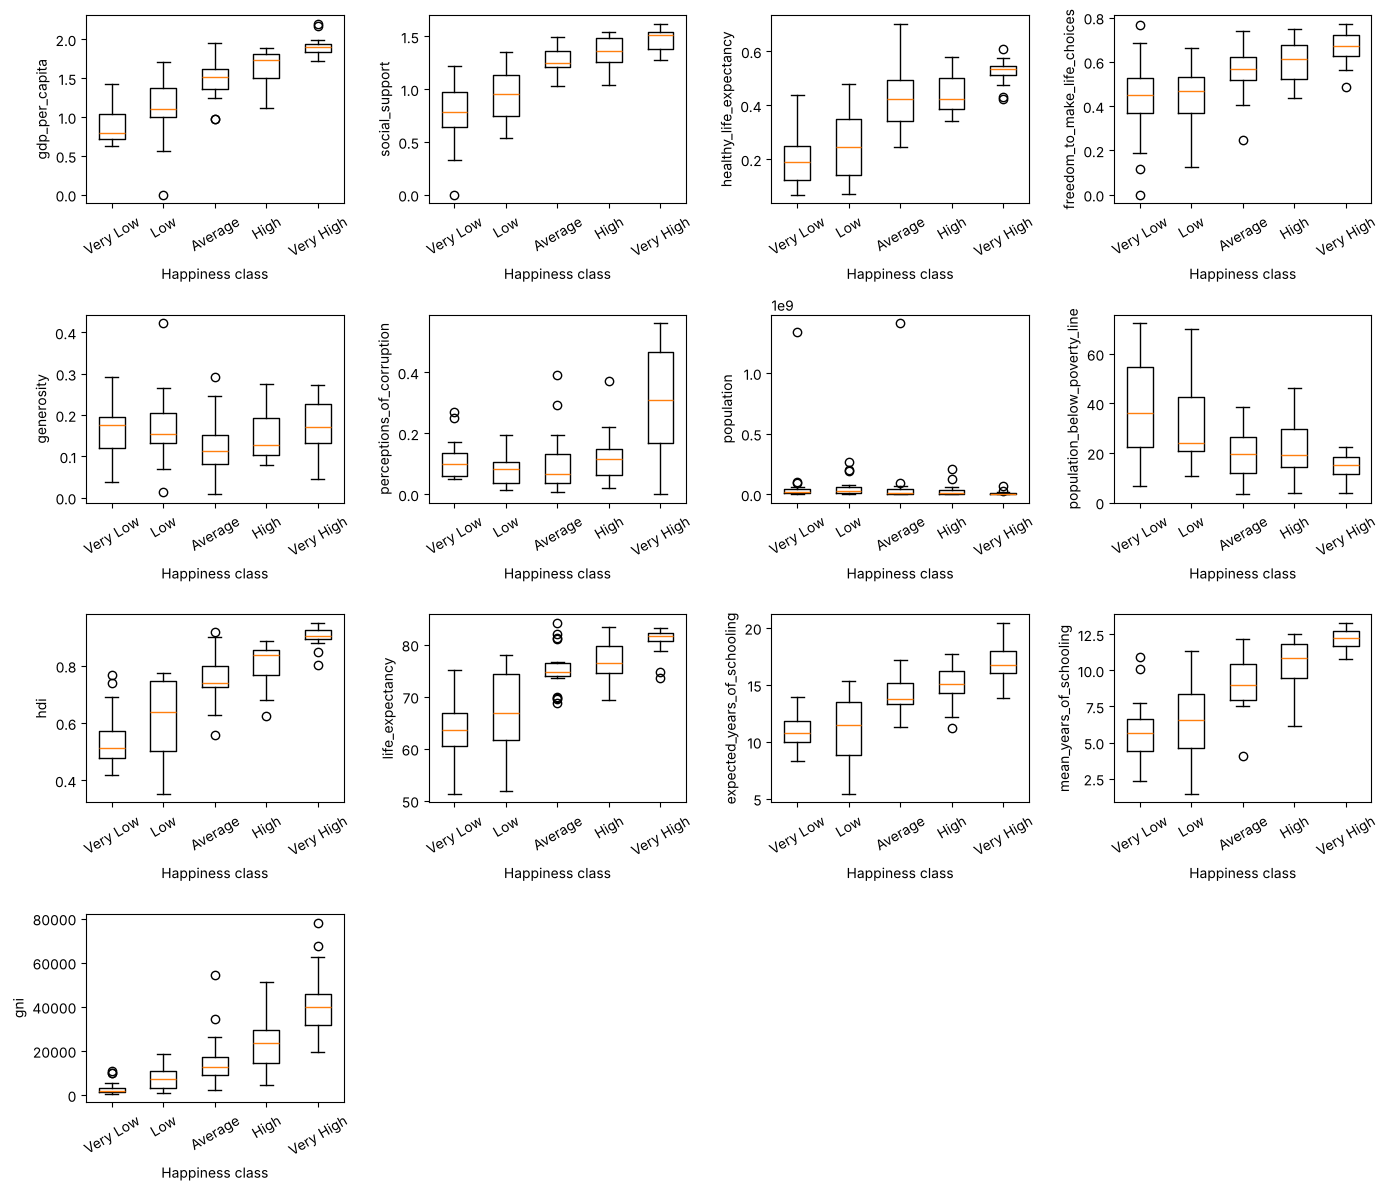

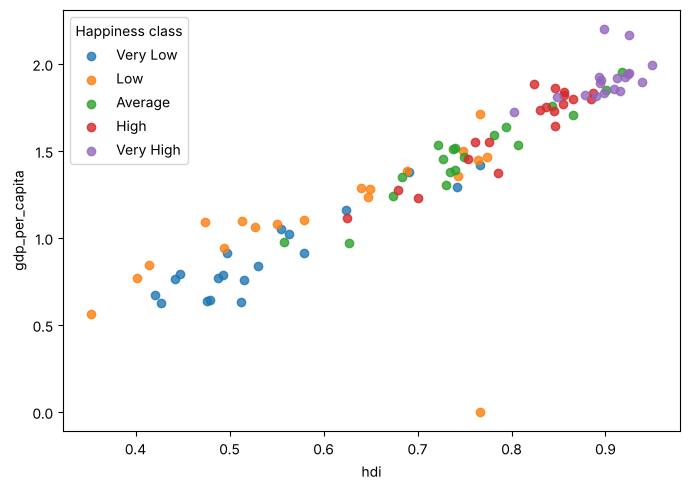

In [14]:
# Correlation of each feature
numeric_cols = X_train.select_dtypes("number").columns.tolist()
class_order = ["Very Low", "Low", "Average", "High", "Very High"]
y_codes = pd.Series(y_train_labels.to_numpy(), index=X_train.index)
y_text = pd.Series(y_train.astype(str).to_numpy(), index=X_train.index)

target_corr = pd.DataFrame({
    "spearman": X_train[numeric_cols].corrwith(y_codes, method="spearman"),
    "pearson": X_train[numeric_cols].corrwith(y_codes, method="pearson"),
}).sort_values("spearman", key=lambda s: s.abs(), ascending=False).round(3)
print(target_corr)

# Median of each feature inside each happiness class
median_by_class = (
    X_train[numeric_cols]
    .groupby(y_text)
    .median()
    .T[class_order]
    .round(3)
)
print(median_by_class)

# Boxplots: features that track the class
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for ax, column in zip(axes.ravel(), numeric_cols):
    data = [
        X_train.loc[y_text == label, column].dropna()
        for label in class_order
    ]
    ax.boxplot(data, tick_labels=class_order)
    ax.set_xlabel("Happiness class")
    ax.set_ylabel(column)
    ax.tick_params(axis="x", rotation=30)
for ax in axes.ravel()[len(numeric_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Scatter of two strongly related development measures, colored by class
fig, ax = plt.subplots(figsize=(7, 5))
for label in class_order:
    subset = X_train.loc[y_text == label]
    ax.scatter(subset["hdi"], subset["gdp_per_capita"], label=label, alpha=0.8)
ax.set_xlabel("hdi")
ax.set_ylabel("gdp_per_capita")
ax.legend(title="Happiness class")
plt.tight_layout()
plt.show()

`gdp_per_capita`, `social_support`, `hdi`, and `gni` have the strongest positive associations with the happiness class (Spearman 0.841, 0.836, 0.828, and 0.825). Schooling, `life_expectancy`, and `healthy_life_expectancy` follow, at about 0.76 to 0.79. Their class medians rise from Very Low to Very High, but neighboring classes overlap, so adjacent classes will be easy to confuse. `population_below_poverty_line` is the main negative association (Spearman -0.479), falling from 36.1 to 15.0. `generosity` is essentially unrelated (-0.004), and `population` is weak and not steady across classes. The useful signal is the shared development cluster; `generosity` and `population` will add little.

### Outlier Detection

Identify potential outliers in the numerical features using appropriate methods such as:

- Box plots
- Z-score analysis
- Interquartile Range (IQR) method

Highlight any significant anomalies and briefly comment on whether they should be retained, transformed, or removed.

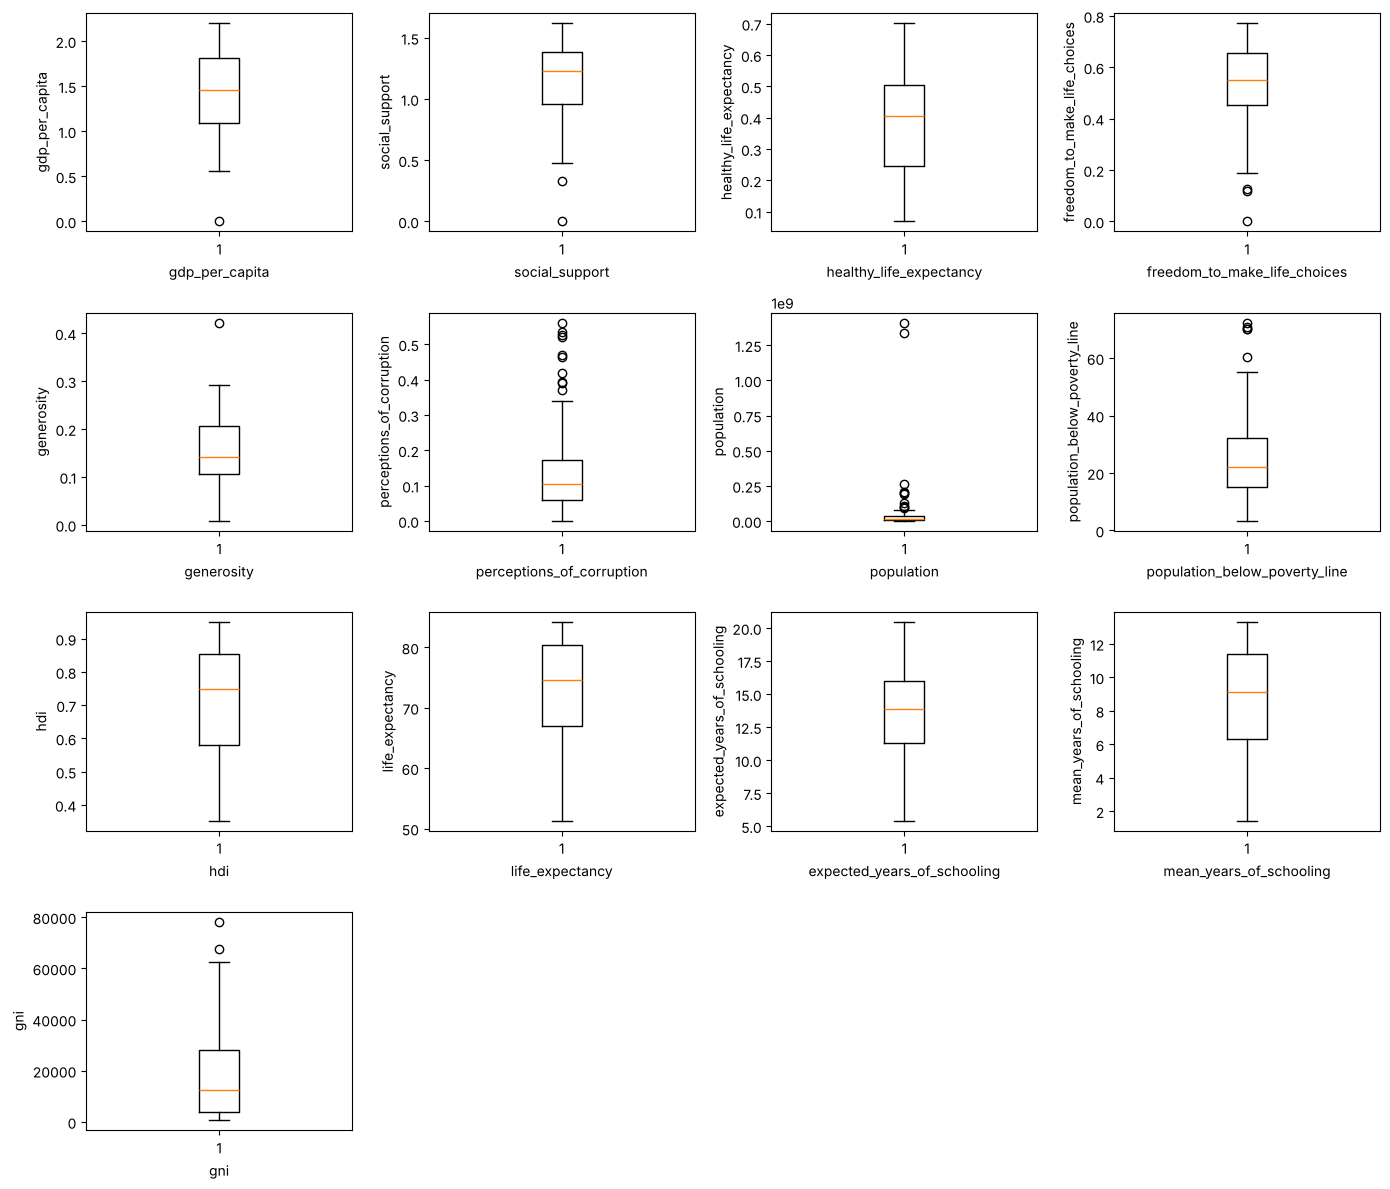

                               iqr_outliers  z_outliers
perceptions_of_corruption                10           1
population                               10           2
population_below_poverty_line             5           0
freedom_to_make_life_choices              3           1
social_support                            2           1
gni                                       2           1
gdp_per_capita                            1           1
generosity                                1           1
healthy_life_expectancy                   0           0
hdi                                       0           0
life_expectancy                           0           0
expected_years_of_schooling               0           0
mean_years_of_schooling                   0           0
gdp_per_capita: 1 ['Venezuela']
social_support: 2 ['Comoros', 'Afghanistan']
healthy_life_expectancy: 0 []
freedom_to_make_life_choices: 3 ['Comoros', 'Afghanistan', 'Turkiye']
generosity: 1 ['Indonesia']
perceptions

In [15]:
# Flag outliers with boxplots, the +-1.5*IQR rule, and |z| > 3
numeric_cols = X_train.select_dtypes("number").columns.tolist()

fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for ax, column in zip(axes.ravel(), numeric_cols):
    ax.boxplot(X_train[column].dropna())
    ax.set_xlabel(column)
    ax.set_ylabel(column)
for ax in axes.ravel()[len(numeric_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

def iqr_outlier(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

iqr_flags = X_train[numeric_cols].apply(iqr_outlier)
z_scores = (X_train[numeric_cols] - X_train[numeric_cols].mean()) / X_train[numeric_cols].std()
z_flags = z_scores.abs() > 3

outlier_counts = pd.DataFrame({
    "iqr_outliers": iqr_flags.sum(),
    "z_outliers": z_flags.sum(),
}).sort_values("iqr_outliers", ascending=False)
print(outlier_counts)

# Print every numeric column and the countries flagged by the IQR rule
for column in numeric_cols:
    flagged = X_train.loc[iqr_flags[column], "country"].tolist()
    print(f"{column}: {len(flagged)}", flagged)

The IQR rule flags 10 countries on `population` (including India and China) and 10 on `perceptions_of_corruption` (mostly high-scoring countries such as Finland, Denmark, and Singapore). `population_below_poverty_line` flags 5, and `gni` flags Norway and Singapore. `|z| > 3` is stricter: only India and China remain for `population`, and only Singapore for `gni` and `perceptions_of_corruption`. These are real countries, not data errors, and the training set has only 95 rows, so none are removed. `population` and `gni` are log-transformed because of their long right tails. The other flagged values are kept as they are.

### Observations and General Comments

Summarize your key findings from the exploratory analysis. Include:

- Important patterns or relationships identified
- Presence of missing values or outliers
- Potential feature engineering considerations
- Any preprocessing steps that should be applied before modeling

Keep your comments concise and evidence-based.

The five happiness classes are balanced, with 19 training countries in each class. `region` is not balanced: Sub-Saharan Africa has 23 countries, while North America and ANZ and the Commonwealth of Independent States have 2 countries each. `gdp_per_capita`, `social_support`, `hdi`, and `gni` rise with the happiness class (Spearman about 0.83 to 0.84). Schooling and life expectancy move with them, and these development columns are strongly correlated with each other (several Pearson correlations are above 0.90), so they describe one level of development. `population_below_poverty_line` falls as the class rises (Spearman -0.479). `generosity` is unrelated, and neighboring classes overlap.

`population_below_poverty_line` is missing for 11 training countries (11.6%). Life expectancy, both schooling measures, and `gni` are missing for 2, and `population` and `hdi` for 1, including unmatched Taiwan. IQR outliers on `population` and `gni` are real large or rich countries, so no rows are deleted. Before modeling, `population` and `gni` are log-transformed, numeric missing values are filled with the training median, features are standardized, and `region` is one-hot encoded.

---

## 2. Feature Engineering

### Log Transformations

Apply log transformations to normalize skewed numerical features and improve model stability (if applicable).

> **Note:** Apply every feature engineering step to **both** `X_train` and `X_test`, before fitting the preprocessor in Section 3.

In [16]:
# Log-transform population and GNI on both the training and test sets
import numpy as np

print(X_train[["population", "gni"]].skew().round(3))

for column in ["population", "gni"]:
    X_train[column] = np.log1p(X_train[column])
    X_test[column] = np.log1p(X_test[column])

print(X_train[["population", "gni"]].skew().round(3))

population    6.212
gni           1.237
dtype: float64
population    0.162
gni          -0.447
dtype: float64


### Interaction Features

Create at least one interaction feature to capture relationships between existing variables and enhance predictive power.

In [17]:
# Multiply social support by freedom so the model can use countries that are high on both
X_train["support_x_freedom"] = X_train["social_support"] * X_train["freedom_to_make_life_choices"]
X_test["support_x_freedom"] = X_test["social_support"] * X_test["freedom_to_make_life_choices"]

---

## 3. Data Preprocessing

Use `sklearn`'s `ColumnTransformer` to preprocess the data. Write a preprocessing function and save the fitted preprocessor for later use.

In [18]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create the preprocessing pipelines for both numeric and categorical data.

numeric_features = X_train.drop(columns=["country", "region", "country_name"])
numeric_features=numeric_features.columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), ## Is this good enough?
    ('scaler', StandardScaler())]) # You will need to describe why this is being done in the next cell

categorical_features = ['region']

#Replacing missing values with Modal value and then one hot encoding.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

# final preprocessor object set up with ColumnTransformer
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features),('cat', categorical_transformer, categorical_features)])

#Fit your preprocessor object
preprocess=preprocessor.fit(X_train)

### Explanation

Briefly explain what the preprocessing steps above do and why they are needed.

If you changed the imputation strategy (or any other preprocessing choice), please state:

- What you changed
- Why you made that change

`country`, `country_name`, and `region` are removed from the numeric columns. `country` and `country_name` identify each row, so they are not used as features. The remaining numeric columns, including `support_x_freedom`, are passed through two steps. I changed the numeric imputer from a constant 0 to `strategy="median"`. Zero is already a real value for several World Happiness factors, and it would be an extreme value for `hdi`, `population`, and `population_below_poverty_line`. The median is computed when `preprocess` is fit on `X_train`. `StandardScaler` then subtracts that training mean and divides by that training standard deviation, so columns with different units do not dominate distance-based models or the neural network. `region` is handled separately: a missing value is filled with the most frequent training region, and `OneHotEncoder` turns the region into 0/1 columns. `handle_unknown="ignore"` keeps an unseen region from stopping the pipeline. The test set is later transformed with `preprocess` and is not used to fit these steps again.

In [19]:
# function to transform data with preprocessor

def preprocessor(data):
    preprocessed_data=preprocess.transform(data)
    return preprocessed_data

### Conceptual Question

Explain the differences between the following:

- The `preprocessor` **object**
- The `preprocess` **object**
- The `preprocessor` **function**
- The final `preprocessed_data` **returned**

Clearly distinguish between objects, functions, and transformed data.

The `preprocessor` object is the `ColumnTransformer` created before fitting. It is the recipe: numeric columns are imputed and scaled, and `region` is imputed and one-hot encoded. `preprocess` is that same transformer after `fit(X_train)`. It stores the training medians, means, standard deviations, and region categories. Defining `def preprocessor` then reuses the name `preprocessor` for a function. The function calls `preprocess.transform` and does not fit anything. `preprocessed_data` is the numeric matrix that the function returns. It is transformed data, not a transformer and not a function.

In [20]:
# check shape of X data after preprocessing it using our new function
preprocessor(X_train).shape

(95, 24)

---

## 4. Model Training and Saving Artifacts

Fit the model on the preprocessed training data. Save the fitted preprocessor and the trained model for reuse (e.g., to make predictions later without retraining).

In [21]:
# Fit a random forest on the preprocessed training data and save both artifacts
# Your cell should have a score between 0-1 as output
from sklearn.ensemble import RandomForestClassifier
import joblib

model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
)
model.fit(preprocessor(X_train), y_train_labels.to_numpy())
print(model.score(preprocessor(X_train), y_train_labels.to_numpy()))

# Save the fitted preprocessor and the trained model for reuse (e.g., using joblib)
joblib.dump(preprocess, "preprocessor.joblib")
joblib.dump(model, "random_forest.joblib")

1.0


['random_forest.joblib']

---

## 5. Model Evaluation

Generate predictions using `X_test`. Compare the predictions with the true labels in `y_test` using appropriate evaluation metrics.

In [22]:
#-- Generate predicted values (Model 1)
prediction_labels = model.predict(preprocessor(X_test))

# Compare the 0-4 predictions with y_test_labels
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, mean_absolute_error, precision_score,
)
from sklearn.dummy import DummyClassifier

class_names = ["Very Low", "Low", "Average", "High", "Very High"]
code_order = [0, 1, 2, 3, 4]
true_codes = y_test_labels.to_numpy()
train_codes = y_train_labels.to_numpy()
X_train_matrix = preprocessor(X_train)
X_test_matrix = preprocessor(X_test)

# Every model in this notebook is scored with the same metrics and stored in `results`,
# which is reused for the comparison tables and the final summary in Section 9.
results = {}

def evaluate(name, test_pred, train_pred):
    """Compute every metric for one model and store the row in `results`."""
    test_pred = np.asarray(test_pred)
    row = {
        "model": name,
        "train_accuracy": accuracy_score(train_codes, train_pred),
        "test_accuracy": accuracy_score(true_codes, test_pred),
        "balanced_accuracy": balanced_accuracy_score(true_codes, test_pred),  # = macro recall
        "macro_precision": precision_score(true_codes, test_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(true_codes, test_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(true_codes, test_pred, average="weighted", zero_division=0),
        "ordinal_MAE": mean_absolute_error(true_codes, test_pred),
        "within_one_class": float(np.mean(np.abs(true_codes - test_pred) <= 1)),
    }
    results[name] = row
    return row

def show_evaluation(name, test_pred, train_pred):
    """Print all metrics, the per-class report, and the confusion matrix for one model."""
    row = evaluate(name, test_pred, train_pred)
    print(pd.Series(row).drop("model").astype(float).round(3).to_string())
    print()
    print(classification_report(true_codes, test_pred, labels=code_order,
                                target_names=class_names, digits=3, zero_division=0))
    print(pd.DataFrame(
        confusion_matrix(true_codes, test_pred, labels=code_order),
        index=[f"true {c}" for c in class_names],
        columns=[f"pred {c}" for c in class_names],
    ))

show_evaluation("RF model 1", prediction_labels, model.predict(X_train_matrix))

# Majority-class baseline for reference
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_matrix, train_codes)
evaluate("Majority-class baseline", baseline.predict(X_test_matrix), baseline.predict(X_train_matrix))
print()
print("majority baseline accuracy", round(results["Majority-class baseline"]["test_accuracy"], 3))

train_accuracy       1.000
test_accuracy        0.548
balanced_accuracy    0.547
macro_precision      0.553
macro_f1             0.545
weighted_f1          0.548
ordinal_MAE          0.452
within_one_class     1.000

              precision    recall  f1-score   support

    Very Low      0.500     0.444     0.471         9
         Low      0.250     0.250     0.250         8
     Average      0.600     0.750     0.667         8
        High      0.556     0.625     0.588         8
   Very High      0.857     0.667     0.750         9

    accuracy                          0.548        42
   macro avg      0.553     0.547     0.545        42
weighted avg      0.559     0.548     0.548        42

                pred Very Low  pred Low  pred Average  pred High  \
true Very Low               4         5             0          0   
true Low                    4         2             2          0   
true Average                0         1             6          1   
true High             


majority baseline accuracy 0.214


Model 1 classifies 23 of the 42 test countries correctly: accuracy 0.548, balanced accuracy 0.547, macro precision 0.553, macro F1 0.545, and weighted F1 0.548, compared with 0.214 accuracy for the majority-class baseline. Its training accuracy is 1.000, so the unlimited-depth forest fits every training country. Every error lands in a neighboring class (within one class = 1.000; ordinal MAE = 0.452), so the forest separates the low and high ends but still confuses adjacent happiness classes, especially Very Low and Low (the Low class has an F1 of only 0.250).

---

## 6. Hyperparameter Experimentation

Repeat the training and evaluation process with different model parameters to improve performance. Track results across experiments and report the best-performing configuration.

In [23]:
# Train model 2 using same preprocessor (note that you could save a new preprocessor, but we will use the same one for this example).
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(
    n_estimators=400,
    max_depth=3,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
)
model_2.fit(preprocessor(X_train), y_train_labels.to_numpy())
print("train accuracy", round(model_2.score(preprocessor(X_train), y_train_labels.to_numpy()), 3))

train accuracy 0.8


### Reflection on Hyperparameter Changes

Briefly explain:

- What parameters you changed
- What each parameter controls
- Why the changes improved (or did not improve) performance

Support your explanation with evidence from your results.

I increased `n_estimators` from 300 to 400, set `max_depth` to 3, and set `min_samples_leaf` to 2 (`max_features="sqrt"` is the default and did not change). `n_estimators` is the number of trees. `max_depth` is the longest path in a tree; Model 1 had no depth limit. `min_samples_leaf` is the smallest number of training countries allowed in a terminal node. Model 1 scored 1.000 on the training set and 0.548 on the test set, so it had memorized the 95 training countries. Model 2 scored 0.800 on training and 0.571 on test, one more correct country (24 of 42). Balanced accuracy rose from 0.547 to 0.569, macro precision from 0.553 to 0.574, macro F1 from 0.545 to 0.566, and weighted F1 from 0.548 to 0.570. Ordinal MAE stayed at 0.452. Within one class fell from 1.000 to 0.976, so one prediction (a Very High country predicted as Average) is now two classes away. The smaller gap between training and test accuracy is the useful change, although a one-country gain on 42 test countries is weak evidence.

In [24]:
#Evaluate Model 2:

#-- Generate predicted y values (Model 2)
prediction_labels = model_2.predict(preprocessor(X_test))

# Same metrics as Model 1
show_evaluation("RF model 2", prediction_labels, model_2.predict(X_train_matrix))

train_accuracy       0.800
test_accuracy        0.571
balanced_accuracy    0.569
macro_precision      0.574
macro_f1             0.566
weighted_f1          0.570
ordinal_MAE          0.452
within_one_class     0.976

              precision    recall  f1-score   support

    Very Low      0.556     0.556     0.556         9
         Low      0.286     0.250     0.267         8
     Average      0.545     0.750     0.632         8
        High      0.625     0.625     0.625         8
   Very High      0.857     0.667     0.750         9

    accuracy                          0.571        42
   macro avg      0.574     0.569     0.566        42
weighted avg      0.580     0.571     0.570        42

                pred Very Low  pred Low  pred Average  pred High  \
true Very Low               5         4             0          0   
true Low                    4         2             2          0   
true Average                0         1             6          1   
true High             

### Discussion Question

Do you think it is worth making more changes to the parameters? Should we keep trying random values and see what works better? What is an alternative to doing this manually?

Further tuning should use a defined search space and training-only validation, rather than repeated tests on the 42 held-out countries. The alternative is cross-validation on the training set. `GridSearchCV` tries a predefined set of parameter combinations and keeps the one with the best average validation score. `RandomizedSearchCV` samples combinations when the grid is large.

### Grid Search (Model 3)

Use `GridSearchCV` to search systematically over Random Forest hyperparameters.

In [25]:
# Train a third model using GridSearchCV

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import numpy as np

# Search tree count, depth, and leaf size with 5-fold cross-validation
param_grid = {
    "n_estimators": np.arange(100, 401, 100),   # 100, 200, 300, 400
    "max_depth": np.arange(2, 7, 2),            # 2, 4, 6
    "min_samples_leaf": np.arange(1, 4)         # 1, 2, 3
}

rf = RandomForestClassifier(random_state=42)
gridmodel = GridSearchCV(rf, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
gridmodel.fit(preprocessor(X_train), y_train_labels.to_numpy())

# extract best score and parameter by calling objects "best_score_" and "best_params_"
print("best mean cross-validation score: {:.3f}".format(gridmodel.best_score_))
print("best parameters: {}".format(gridmodel.best_params_))

# Make predictions using the best model
prediction_labels = gridmodel.predict(preprocessor(X_test))

best mean cross-validation score: 0.621
best parameters: {'max_depth': np.int64(4), 'min_samples_leaf': np.int64(1), 'n_estimators': np.int64(300)}


In [26]:
#Evaluate Model 3:
# prediction_labels holds the grid-search predictions from the cell above
show_evaluation("RF model 3 (grid search)", prediction_labels, gridmodel.predict(X_train_matrix))

train_accuracy       0.958
test_accuracy        0.524
balanced_accuracy    0.522
macro_precision      0.536
macro_f1             0.521
weighted_f1          0.525
ordinal_MAE          0.500
within_one_class     0.976

              precision    recall  f1-score   support

    Very Low      0.500     0.444     0.471         9
         Low      0.250     0.250     0.250         8
     Average      0.500     0.750     0.600         8
        High      0.571     0.500     0.533         8
   Very High      0.857     0.667     0.750         9

    accuracy                          0.524        42
   macro avg      0.536     0.522     0.521        42
weighted avg      0.543     0.524     0.525        42

                pred Very Low  pred Low  pred Average  pred High  \
true Very Low               4         5             0          0   
true Low                    4         2             2          0   
true Average                0         1             6          1   
true High             

### Other Classical Models

Train at least one other model from the list below and compare it with your Random Forest models.

In [27]:
# Here are several classic ML architectures you can consider choosing from to experiment with next:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import GradientBoostingClassifier

candidates = {
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "SVC": SVC(C=1, kernel="rbf"),
    "Bagging": BaggingClassifier(n_estimators=100, random_state=42),
    "Gradient boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42
    ),
}

for name, candidate in candidates.items():
    candidate.fit(X_train_matrix, train_codes)
    evaluate(name, candidate.predict(X_test_matrix), candidate.predict(X_train_matrix))

# Compare the three random forests, the four other classical models, and the baseline on every metric
classical_names = [
    "RF model 1", "RF model 2", "RF model 3 (grid search)",
    "KNN", "SVC", "Bagging", "Gradient boosting", "Majority-class baseline",
]
comparison = (
    pd.DataFrame([results[name] for name in classical_names])
    .sort_values(["test_accuracy", "macro_f1"], ascending=False)
    .reset_index(drop=True)
)
comparison.round(3)

,model,train_accuracy,test_accuracy,balanced_accuracy,macro_precision,macro_f1,weighted_f1,ordinal_MAE,within_one_class
0,RF model 2,0.800,0.571,0.569,0.574,0.566,0.570,0.452,0.976
1,Bagging,1.000,0.548,0.547,0.561,0.547,0.551,0.452,1.000
2,SVC,0.747,0.548,0.544,0.586,0.545,0.552,0.452,1.000
3,RF model 1,1.000,0.548,0.547,0.553,0.545,0.548,0.452,1.000
4,RF model 3 (grid search),0.958,0.524,0.522,0.536,0.521,0.525,0.500,0.976
5,KNN,0.621,0.500,0.506,0.576,0.504,0.505,0.571,0.929
6,Gradient boosting,1.000,0.452,0.450,0.455,0.447,0.452,0.571,0.976
7,Majority-class baseline,0.200,0.214,0.200,0.043,0.071,0.076,2.000,0.405


### Discussion Question

Describe the parameters you defined in `GradientBoostingClassifier`, and/or `BaggingClassifier`, and/or `KNN`, and/or `SVC`. What worked and why?

`KNeighborsClassifier` uses `n_neighbors=7`, so each country is labeled by a vote of its seven nearest training countries in the standardized feature space. It had the lowest training accuracy (0.621) and a test accuracy of 0.500 (macro F1 0.504, ordinal MAE 0.571), and three test countries were placed two classes away (within one class 0.929). `SVC` uses `kernel="rbf"` and `C=1`. The RBF kernel allows a curved boundary, and `C` is the penalty for training errors. It scored 0.747 on training and 0.548 on test, with macro F1 0.545 and the highest macro precision of the classical models (0.586), matching the first random forest without memorizing the sample. `BaggingClassifier` uses `n_estimators=100` bootstrap trees. Its training accuracy was 1.000 and its test accuracy was 0.548 (macro F1 0.547). `GradientBoostingClassifier` uses 100 trees, `learning_rate=0.05`, and `max_depth=2`. `learning_rate` shrinks each new tree and `max_depth` limits each correction, but training accuracy was still 1.000 and test accuracy was 0.452 (macro F1 0.447), the weakest of the four. The support-vector classifier worked best among these four, because its training and test scores stay close and its precision is the highest. It did not beat RF model 2, which leads the classical models on test accuracy (0.571), balanced accuracy (0.569), and macro F1 (0.566).

---

## 7. Basic Deep Learning

In [28]:
# Now experiment with deep learning models:
import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Activation

# Reproducibility: without a fixed seed, every run starts from different random weights and
# gives different scores. keras.utils.set_random_seed() is called before each network is built,
# so Restart & Run All reproduces the same numbers.
SEED = 42
tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel("ERROR")  # hide repeated tf.function retracing warnings

# Preprocess input features
X_train_matrix = preprocessor(X_train)
X_test_matrix = preprocessor(X_test)
feature_count = X_train_matrix.shape[1]

# Encode categorical labels as one-hot and store them in y_train_oh (e.g., with pd.get_dummies)
y_train_oh = pd.get_dummies(y_train_labels).reindex(columns=[0, 1, 2, 3, 4]).astype(float)

# Define a Neural Network Model with 5 layers 128->64->64->32->5
# Use Softmax activation in last layer. How many neurons should there be in the last layer? ——> 5
keras.utils.set_random_seed(SEED)
keras_model = Sequential([
    keras.Input(shape=(feature_count,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(5, activation="softmax"),
])

# Compile model
keras_model.compile(loss="categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])

# Fitting the NN to the Training set
history = keras_model.fit(
    X_train_matrix,
    y_train_oh,
    batch_size=20,
    epochs=300,
    validation_split=0.25,
    verbose=0,
)

I0000 00:00:1792170054.464734   26878 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792170054.467568   26878 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792170057.070392   26878 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792170057.073439   26878 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Discussion Question

Which activation functions did you use in the hidden layers? Why was **softmax** used in the final layer?

The hidden layers use ReLU. It outputs zero for a negative input and leaves a positive input unchanged, so the gradient remains usable on the positive side. The final layer uses softmax because there are five classes. Its five outputs are probabilities and sum to 1, and the predicted label is the column with the largest probability.

### Discussion Question

Was it a good idea to train for 300 epochs? Should you train longer? Why or why not?

300 epochs is too long for 95 countries. A quarter of the training matrix is held out for validation, so the weights are updated on 71 rows. The learning curves below show the turn: validation loss is lowest at epoch 123 (1.240) and then rises to 2.018 by epoch 300, while training loss keeps falling to 0.182 and training accuracy climbs to 0.986. Validation accuracy ends at only 0.417. After about epoch 120 the extra epochs fit the training countries instead of improving generalization, so I would not train longer. I would stop near the lowest validation loss, for example with `EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)`.

### Discussion Question

Why was `loss='categorical_crossentropy'` and `optimizer='sgd'` used? Would you change anything? Why or why not?

`categorical_crossentropy` is the loss for one-hot multi-class labels. It penalizes the model when the true class receives a low probability. `sgd` updates the weights with a fixed step size. I would keep the loss. I would change the optimizer to Adam, because it uses a separate step size for each weight and usually reaches a stable validation loss sooner on this small network.

### Plot Training Curves

Extract the model training history and plot the learning curves (e.g., training vs. validation loss and accuracy) across epochs.

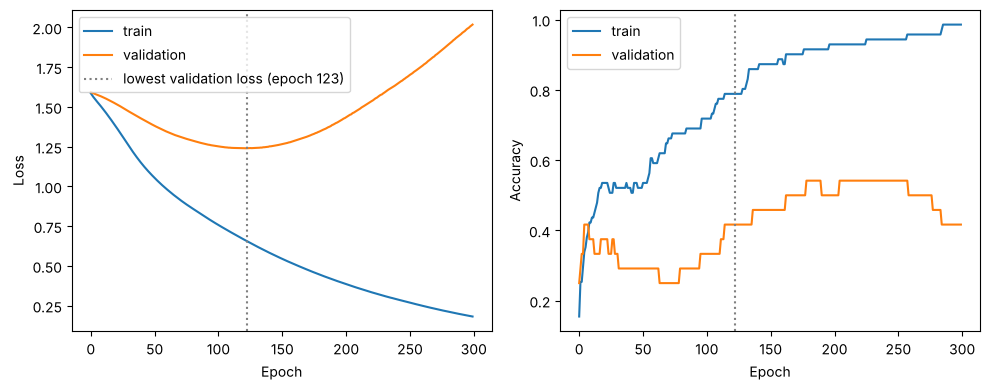

lowest validation loss: 1.24 at epoch 123
epoch 300 train loss: 0.182 | validation loss: 2.018
epoch 300 train accuracy: 0.986 | validation accuracy: 0.417


In [29]:
# Plot training and validation loss and accuracy across epochs
import matplotlib.pyplot as plt

best_epoch = int(np.argmin(history.history["val_loss"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].axvline(best_epoch - 1, color="gray", linestyle=":", label=f"lowest validation loss (epoch {best_epoch})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].axvline(best_epoch - 1, color="gray", linestyle=":")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

print("lowest validation loss:", round(min(history.history["val_loss"]), 3), "at epoch", best_epoch)
print("epoch 300 train loss:", round(history.history["loss"][-1], 3),
      "| validation loss:", round(history.history["val_loss"][-1], 3))
print("epoch 300 train accuracy:", round(history.history["accuracy"][-1], 3),
      "| validation accuracy:", round(history.history["val_accuracy"][-1], 3))

### Evaluate the Neural Network on the Test Set

In [30]:
#-- Generate predicted y values
#Note: Keras predict returns class probabilities (one column per class).
#Use np.argmax(..., axis=1) to get the predicted column index for each row.
def nn_predict(network, matrix):
    """Return the predicted 0-4 label for each row of `matrix`."""
    prediction_column_index = np.argmax(network.predict(matrix, verbose=0), axis=1)
    # extract correct prediction labels
    return np.array([y_train_oh.columns[i] for i in prediction_column_index])

prediction_labels = nn_predict(keras_model, X_test_matrix)

# Train accuracy is computed on all 95 training countries (including the 25% validation split)
show_evaluation("ReLU network", prediction_labels, nn_predict(keras_model, X_train_matrix))

train_accuracy       0.842
test_accuracy        0.548
balanced_accuracy    0.544
macro_precision      0.550
macro_f1             0.545
weighted_f1          0.548
ordinal_MAE          0.452
within_one_class     1.000

              precision    recall  f1-score   support

    Very Low      0.500     0.444     0.471         9
         Low      0.333     0.375     0.353         8
     Average      0.714     0.625     0.667         8
        High      0.500     0.500     0.500         8
   Very High      0.700     0.778     0.737         9

    accuracy                          0.548        42
   macro avg      0.550     0.544     0.545        42
weighted avg      0.552     0.548     0.548        42

                pred Very Low  pred Low  pred Average  pred High  \
true Very Low               4         5             0          0   
true Low                    4         3             1          0   
true Average                0         1             5          2   
true High             

### Regularization: Dropout and Batch Normalization

Implement regularization techniques such as **Dropout** and **Batch Normalization** to improve generalization and observe the change in performance.

> **Note:** Compare training vs. test (or validation) loss and accuracy before and after adding regularization.

train_accuracy       0.832
test_accuracy        0.595
balanced_accuracy    0.592
macro_precision      0.612
macro_f1             0.590
weighted_f1          0.595
ordinal_MAE          0.476
within_one_class     0.929

              precision    recall  f1-score   support

    Very Low      0.556     0.556     0.556         9
         Low      0.500     0.375     0.429         8
     Average      0.462     0.750     0.571         8
        High      0.667     0.500     0.571         8
   Very High      0.875     0.778     0.824         9

    accuracy                          0.595        42
   macro avg      0.612     0.592     0.590        42
weighted avg      0.617     0.595     0.595        42

                pred Very Low  pred Low  pred Average  pred High  \
true Very Low               5         3             1          0   
true Low                    4         3             1          0   
true Average                0         0             6          2   
true High             

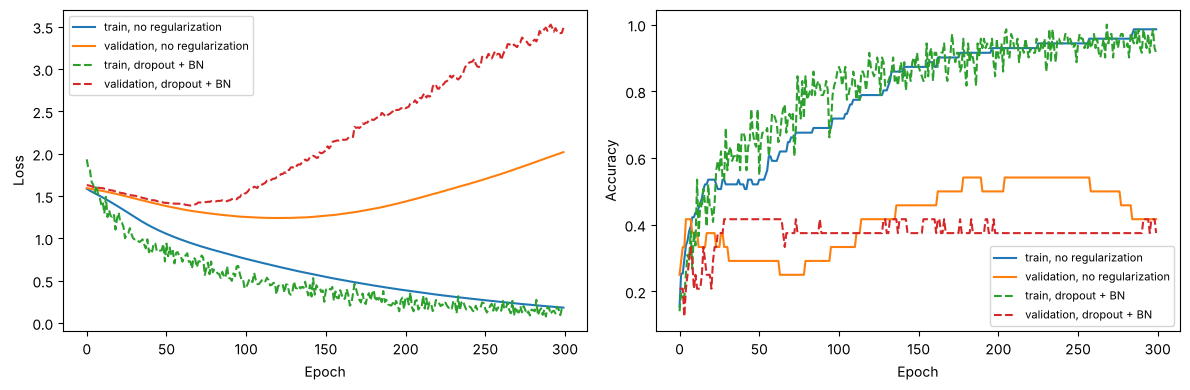

In [31]:
# Retrain the same network with batch normalization and dropout
from keras.layers import Dropout, BatchNormalization

keras.utils.set_random_seed(SEED)
keras_reg = Sequential([
    keras.Input(shape=(feature_count,)),
    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(5, activation="softmax"),
])
keras_reg.compile(loss="categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])
history_reg = keras_reg.fit(
    X_train_matrix, y_train_oh,
    batch_size=20, epochs=300, validation_split=0.25, verbose=0,
)

reg_labels = nn_predict(keras_reg, X_test_matrix)
show_evaluation("ReLU network + dropout/BN", reg_labels, nn_predict(keras_reg, X_train_matrix))

# Training vs. validation loss and accuracy, before and after regularization
def curve_summary(h):
    best = int(np.argmin(h.history["val_loss"]))
    return {
        "epoch 300 train loss": h.history["loss"][-1],
        "epoch 300 validation loss": h.history["val_loss"][-1],
        "epoch 300 train accuracy": h.history["accuracy"][-1],
        "epoch 300 validation accuracy": h.history["val_accuracy"][-1],
        "lowest validation loss": h.history["val_loss"][best],
        "epoch of lowest validation loss": best + 1,
    }

print()
print("Learning-curve summary")
print(pd.DataFrame({
    "ReLU network": curve_summary(history),
    "ReLU network + dropout/BN": curve_summary(history_reg),
}).round(3))
print()
print("Test-set metrics")
print(pd.DataFrame([results["ReLU network"], results["ReLU network + dropout/BN"]])
      .set_index("model").T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for h, name, style in [(history, "no regularization", "-"), (history_reg, "dropout + BN", "--")]:
    axes[0].plot(h.history["loss"], linestyle=style, label=f"train, {name}")
    axes[0].plot(h.history["val_loss"], linestyle=style, label=f"validation, {name}")
    axes[1].plot(h.history["accuracy"], linestyle=style, label=f"train, {name}")
    axes[1].plot(h.history["val_accuracy"], linestyle=style, label=f"validation, {name}")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

I added `BatchNormalization` after the first two hidden layers and `Dropout(0.3)` after the first three, keeping the same seed, data, and training settings. The evidence is mixed.

- **Test set:** the regularized network is better on most metrics. Accuracy rose from 0.548 to 0.595 (23 to 25 of 42 countries), balanced accuracy from 0.544 to 0.592, macro precision from 0.550 to 0.612, macro F1 from 0.545 to 0.590, and weighted F1 from 0.548 to 0.595. However, ordinal MAE worsened from 0.452 to 0.476 and within one class fell from 1.000 to 0.929, so three countries are now two classes away.
- **Training vs. validation:** at epoch 300, training loss was 0.168 with regularization and 0.182 without, and training accuracy was 0.915 versus 0.986 (the regularized training scores are measured with dropout active). Validation loss was 3.486 versus 2.018, and validation accuracy was 0.375 versus 0.417. The regularized network reached its lowest validation loss earlier (1.388 at epoch 66, versus 1.240 at epoch 123) and then overfit faster.
- **Gap:** on all 95 training countries, training accuracy was 0.832 versus 0.842, so the train–test accuracy gap narrowed from 0.294 to 0.237.

Dropout and batch normalization narrowed the train–test gap and helped the test scores, but the validation curves got worse. With only 24 validation and 42 test countries, a two-country gain is within noise, so the regularization did not clearly improve generalization; early stopping would matter more than either layer.

### Activation Function Experimentation

Experiment with different activation functions — **ReLU**, **LeakyReLU**, **Tanh**, and **Sigmoid** — and compare their impact on model performance.

In [32]:
# Train the same five-layer network with four hidden-layer activations
from keras.layers import LeakyReLU

def build_activation_model(activation):
    network = Sequential([keras.Input(shape=(feature_count,))])
    for width in (128, 64, 64, 32):
        if activation == "leaky_relu":
            network.add(Dense(width))
            network.add(LeakyReLU(negative_slope=0.1))
        else:
            network.add(Dense(width, activation=activation))
    network.add(Dense(5, activation="softmax"))
    network.compile(loss="categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])
    return network

activation_names = ["relu", "leaky_relu", "tanh", "sigmoid"]
activation_histories = {}
for activation in activation_names:
    keras.utils.set_random_seed(SEED)
    candidate = build_activation_model(activation)
    activation_histories[activation] = candidate.fit(
        X_train_matrix, y_train_oh, batch_size=20, epochs=300, validation_split=0.25, verbose=0
    )
    evaluate(f"{activation} network", nn_predict(candidate, X_test_matrix), nn_predict(candidate, X_train_matrix))

# All metrics for the four activations, plus the validation scores at epoch 300
activation_table = pd.DataFrame([results[f"{a} network"] for a in activation_names])
activation_table["val_accuracy_epoch_300"] = [activation_histories[a].history["val_accuracy"][-1] for a in activation_names]
activation_table["val_loss_epoch_300"] = [activation_histories[a].history["val_loss"][-1] for a in activation_names]
activation_table.round(3)

,model,train_accuracy,test_accuracy,balanced_accuracy,macro_precision,macro_f1,weighted_f1,ordinal_MAE,within_one_class,val_accuracy_epoch_300,val_loss_epoch_300
0,relu network,0.842,0.548,0.544,0.550,0.545,0.548,0.452,1.000,0.417,2.018
1,leaky_relu network,0.853,0.548,0.544,0.550,0.545,0.548,0.452,1.000,0.458,1.903
2,tanh network,0.842,0.476,0.469,0.473,0.466,0.472,0.595,0.952,0.417,1.964
3,sigmoid network,0.200,0.214,0.200,0.043,0.071,0.076,2.000,0.405,0.125,1.662


ReLU, LeakyReLU (slope 0.1), tanh, and sigmoid were trained in the same five-layer network with the same seed, SGD, and 300 epochs, with softmax kept in the output layer. ReLU and LeakyReLU keep a usable gradient for positive inputs, and LeakyReLU also keeps a small gradient for negative inputs. tanh and sigmoid flatten at both ends. ReLU and LeakyReLU tied on the test set: accuracy 0.548, balanced accuracy 0.544, macro F1 0.545, ordinal MAE 0.452, and every error within one class; LeakyReLU had a slightly higher final validation accuracy (0.458 versus 0.417). The ReLU run reproduces the first network exactly because it uses the same seed and architecture. tanh was weaker (accuracy 0.476, macro F1 0.466, ordinal MAE 0.595). Sigmoid predicted the same class for every country: its training accuracy was 0.200, its test accuracy of 0.214 matched the majority-class baseline, and its macro F1 was 0.071. Four stacked sigmoid layers shrink the gradient at each layer, so with plain SGD the network did not learn to separate the classes in 300 epochs. ReLU and LeakyReLU are the better choices here.

---

## 8. Explainability – SHAP Feature Importance

To better understand the model's predictions, we will use **SHAP (SHapley Additive exPlanations)** to analyze feature importance.

**How SHAP works:**

- SHAP assigns each feature a contribution score for every prediction.
- It uses Shapley values (from cooperative game theory) to fairly distribute importance across features.

We will apply SHAP to visualize and interpret the model's feature contributions.

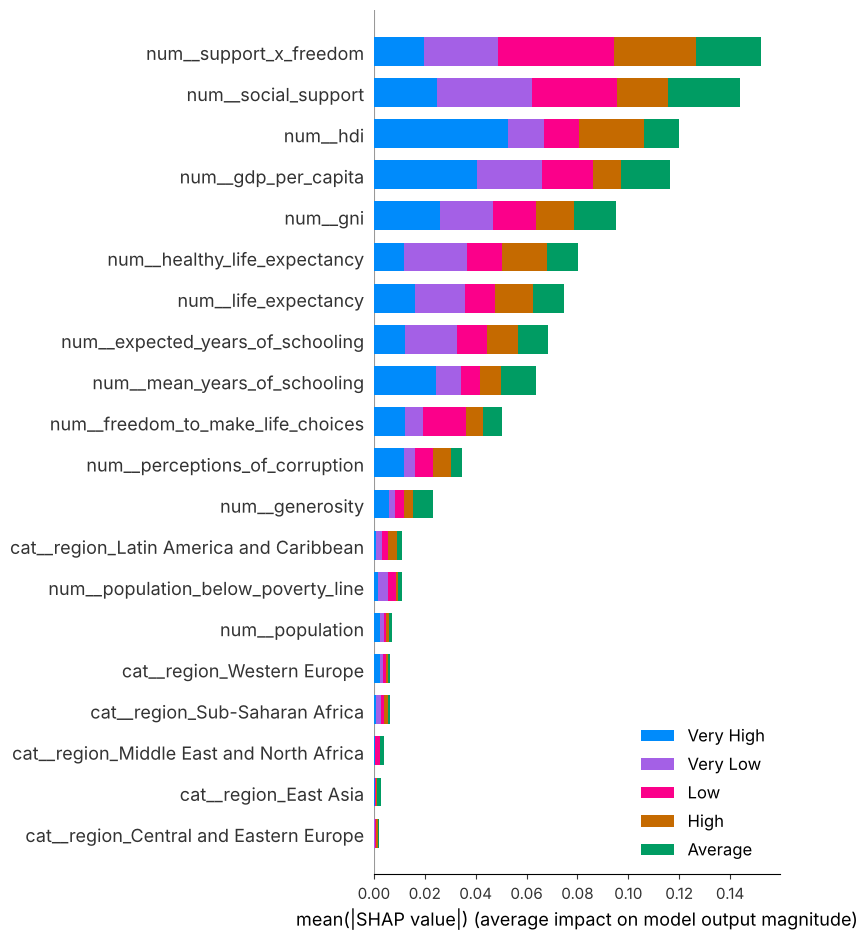

num__support_x_freedom               0.152
num__social_support                  0.144
num__hdi                             0.120
num__gdp_per_capita                  0.116
num__gni                             0.095
num__healthy_life_expectancy         0.080
num__life_expectancy                 0.075
num__expected_years_of_schooling     0.068
num__mean_years_of_schooling         0.064
num__freedom_to_make_life_choices    0.050
dtype: float64


In [33]:
# Explain RF model 2 with SHAP on the preprocessed test matrix
# Import necessary libraries
import shap
import warnings
import matplotlib.pyplot as plt

# shap's plotting code warns about NumPy's global RNG being seeded; the warning does not affect the values
warnings.filterwarnings("ignore", message="The NumPy global RNG was seeded")

# Transform the test data using the fitted preprocessor
# (SHAP needs the same numeric feature matrix the model was trained on, not raw X_test)
X_test_matrix = preprocessor(X_test)

# Get feature names matching the columns after preprocessing
# (Hint: preprocess.get_feature_names_out())
feature_names = preprocess.get_feature_names_out()
X_test_df = pd.DataFrame(X_test_matrix, columns=feature_names)

# Initialize SHAP explainer
# Define an explainer that will help us interpret the model's decisions
# We explain RF model 2, the tree model with the best test accuracy and macro F1 (see the comparison table)
explainer = shap.TreeExplainer(model_2)

# Compute SHAP values for the preprocessed test data
# This step generates Shapley values, which explain how each feature contributes to predictions
shap_values = explainer.shap_values(X_test_df)

# One (countries x features) matrix per class
if isinstance(shap_values, list):
    rf_per_class = shap_values
else:
    values = np.asarray(shap_values)
    rf_per_class = [values[:, :, i] for i in range(values.shape[2])] if values.ndim == 3 else [values]

# Generate SHAP summary plot
# This plot will show which features have the most impact on predictions
shap.summary_plot(rf_per_class, X_test_df, class_names=class_names)

# Bar length in the plot = mean |SHAP value| summed over the five classes
rf_importance = pd.Series(
    np.sum([np.abs(v).mean(axis=0) for v in rf_per_class], axis=0), index=feature_names
).sort_values(ascending=False)
print(rf_importance.head(10).round(3))

We explain RF model 2 because it is the tree model with the best test accuracy (0.571) and macro F1 (0.566); the grid-search forest had a higher cross-validation score but a lower test score. The plot ranks features by mean absolute SHAP value summed over the five classes, and each color is one happiness class. The strongest contribution comes from `support_x_freedom` (0.152), followed by `social_support` (0.144), `hdi` (0.120), `gdp_per_capita` (0.116), and `gni` (0.095). `healthy_life_expectancy`, `life_expectancy`, and the two schooling measures come next. The largest part of `hdi`'s contribution goes to the Very High class. `freedom_to_make_life_choices` alone (0.050) is shorter than its interaction with `social_support`, and `perceptions_of_corruption`, `generosity`, `population`, and the region indicators contribute little.

### Explaining the Deep Learning Model

Deep learning models are often considered "black boxes" due to their complexity. Use SHAP to explain your model's predictions.

After applying SHAP, discuss:

- Does it provide a clear and sufficient explanation of how the model makes decisions?
- How easy or difficult is it to justify your model's predictions using this technique?

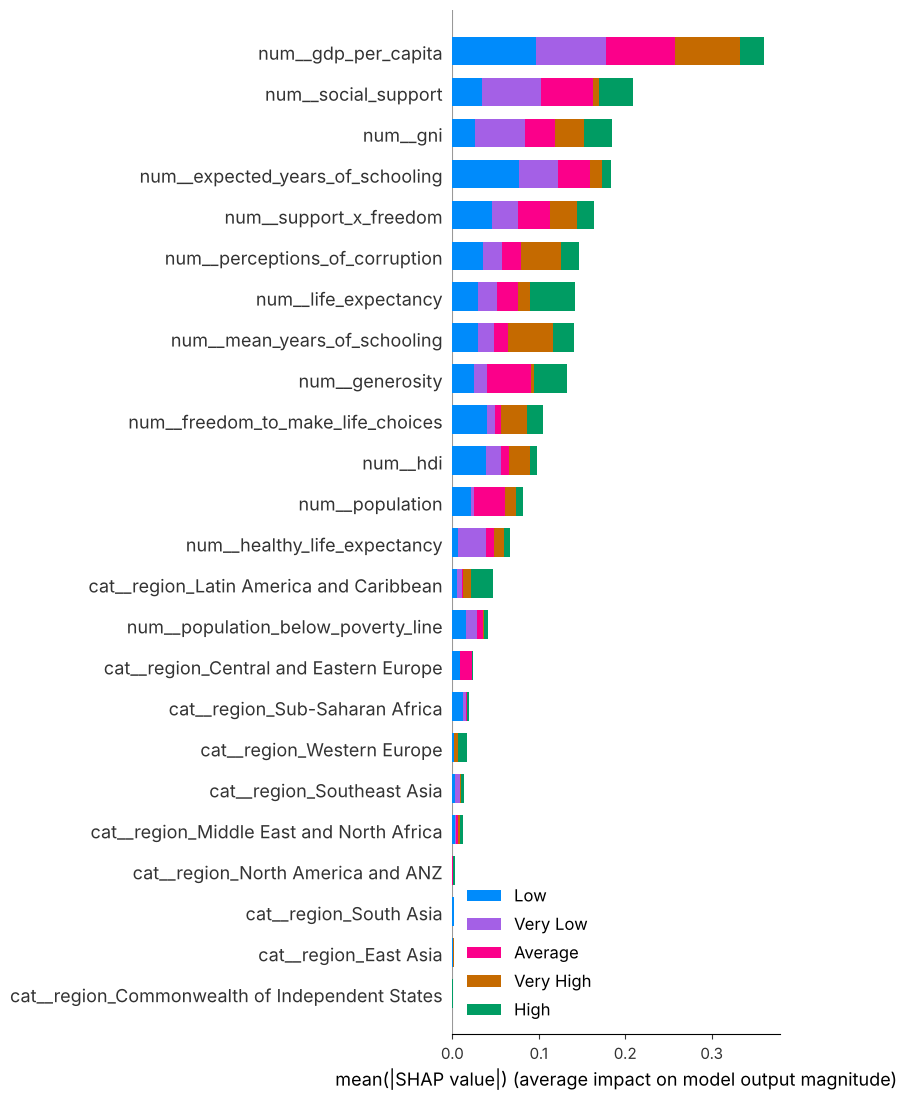

num__gdp_per_capita                  0.361
num__social_support                  0.209
num__gni                             0.184
num__expected_years_of_schooling     0.184
num__support_x_freedom               0.163
num__perceptions_of_corruption       0.146
num__life_expectancy                 0.142
num__mean_years_of_schooling         0.140
num__generosity                      0.133
num__freedom_to_make_life_choices    0.105
dtype: float64


In [34]:
# Explain the ReLU network on the 42 test countries
import shap

X_train_matrix = preprocessor(X_train)
X_test_matrix = preprocessor(X_test)
feature_names = preprocess.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_matrix, columns=feature_names)
X_test_df = pd.DataFrame(X_test_matrix, columns=feature_names)

background = X_train_df
np.random.seed(SEED)  # KernelExplainer samples feature coalitions at random
explainer_nn = shap.KernelExplainer(
    lambda data: keras_model.predict(np.asarray(data), verbose=0),
    background,
)
shap_nn = explainer_nn.shap_values(X_test_df, silent=True)
# The last dimension is the 5 classes. Plot one matrix per class.
if isinstance(shap_nn, list):
    per_class = shap_nn
else:
    arr = np.asarray(shap_nn)
    per_class = [arr[:, :, i] for i in range(arr.shape[-1])]
shap.summary_plot(per_class, X_test_df, max_display=X_test_df.shape[1], class_names=class_names, show=False)
plt.tight_layout()
plt.savefig("shap_neural_net.png", dpi=200, bbox_inches="tight")
plt.show()

# Bar length in the plot = mean |SHAP value| summed over the five classes
nn_importance = pd.Series(
    np.sum([np.abs(v).mean(axis=0) for v in per_class], axis=0), index=feature_names
).sort_values(ascending=False)
print(nn_importance.head(10).round(3))

The SHAP summary for the ReLU network ranks every feature by its mean absolute contribution to the five class probabilities, summed over classes. `gdp_per_capita` has by far the longest bar (0.361), followed by `social_support` (0.209), `gni` (0.184), `expected_years_of_schooling` (0.184), and `support_x_freedom` (0.163). `perceptions_of_corruption`, `life_expectancy`, `mean_years_of_schooling`, and `generosity` come next. `hdi` ranks 11th, much lower than in the forest, and the `region` indicators are short. Both models rely on the same development and social-support signal, but they divide the credit among the correlated columns differently.

The explanation is useful but not sufficient. The ranking is readable, but `KernelExplainer` estimates the values by perturbing the inputs against a background sample, so they are approximations, and the bar length does not show the direction of the effect. Because many features are strongly correlated (for example `gdp_per_capita`, `gni`, and `hdi`), credit can shift between them, so it is hard to say which one the network actually relies on. Justifying one country's predicted class is therefore more difficult than with the forest, whose SHAP values follow explicit tree splits and are computed exactly by `TreeExplainer`.

### Experimentation

In [35]:
## You are encouraged to try more experimentation and any other models by adding more code cells to this notebook:

## You can also try to import any new dataset pertaining to countries, merge it, and see if it helps the predictions.
## If it does not, try to explain why it wasn't helpful by exploring variable relationships.

---

## 9. Final Summary

Summarize your project in a few short paragraphs. Include:

- A table comparing the test performance of every model you trained
- Your best-performing model, its hyperparameters, and why you think it performed best
- The most important insights from your EDA and SHAP analysis
- Limitations of your approach and what you would try next

In [36]:
# Compare test performance for every model trained above.
# The table is built from `results`, which every evaluation cell filled in,
# so it always matches the outputs above after Restart & Run All.
# "relu network" from the activation experiment is the same architecture, seed, and data as
# "ReLU network", so it gives identical results and is listed once.
summary = (
    pd.DataFrame([row for name, row in results.items() if name != "relu network"])
    .sort_values(["test_accuracy", "macro_f1"], ascending=False)
    .reset_index(drop=True)
)
summary.round(3)

,model,train_accuracy,test_accuracy,balanced_accuracy,macro_precision,macro_f1,weighted_f1,ordinal_MAE,within_one_class
0,ReLU network + dropout/BN,0.832,0.595,0.592,0.612,0.590,0.595,0.476,0.929
1,RF model 2,0.800,0.571,0.569,0.574,0.566,0.570,0.452,0.976
2,Bagging,1.000,0.548,0.547,0.561,0.547,0.551,0.452,1.000
3,SVC,0.747,0.548,0.544,0.586,0.545,0.552,0.452,1.000
4,ReLU network,0.842,0.548,0.544,0.550,0.545,0.548,0.452,1.000
5,leaky_relu network,0.853,0.548,0.544,0.550,0.545,0.548,0.452,1.000
6,RF model 1,1.000,0.548,0.547,0.553,0.545,0.548,0.452,1.000
7,RF model 3 (grid search),0.958,0.524,0.522,0.536,0.521,0.525,0.500,0.976
8,KNN,0.621,0.500,0.506,0.576,0.504,0.505,0.571,0.929
9,tanh network,0.842,0.476,0.469,0.473,0.466,0.472,0.595,0.952


The table above compares every model on the same eight metrics. On the test set, the ReLU network with dropout and batch normalization ranks first on accuracy (0.595, 25 of 42 countries), balanced accuracy (0.592), macro precision (0.612), macro F1 (0.590), and weighted F1 (0.595). It uses layers of 128, 64, 64, 32, and 5 units, ReLU in the hidden layers, batch normalization after the first two hidden layers, `Dropout(0.3)` after the first three, a softmax output, `categorical_crossentropy`, and SGD for 300 epochs with batch size 20, a 25% validation split, and seed 42. Dropout and batch normalization keep the network from relying on individual units and narrow the train–test gap (0.832 versus 0.595, compared with 0.842 versus 0.548 without them), which is the most likely reason it did best. Its lead is small and not consistent across metrics, however: it is one country ahead of RF model 2 (0.571), its ordinal MAE (0.476) and within-one-class rate (0.929) are worse than RF model 2's (0.452 and 0.976), and its validation loss was the highest of the networks. RF model 2 (400 trees, `max_depth=3`, `min_samples_leaf=2`) is the best tree model and the more stable choice. The grid-search forest had the best cross-validation score, 0.621, but its test accuracy was 0.524. The unregularized ReLU and LeakyReLU networks tied at 0.548, tanh reached 0.476, and sigmoid matched the majority-class baseline of 0.214.

`gdp_per_capita`, `social_support`, `hdi`, and `gni` rise with the happiness class, with Spearman correlations of about 0.83 to 0.84. Schooling and life expectancy move with them, and these development columns are strongly correlated with one another. `population_below_poverty_line` is negatively associated with the class, and `generosity` is not. In the forest SHAP plot, the longest bars are `support_x_freedom`, `social_support`, `hdi`, `gdp_per_capita`, and `gni`. In the ReLU network they are `gdp_per_capita`, `social_support`, `gni`, `expected_years_of_schooling`, and `support_x_freedom`; `hdi` ranks lower, and the `region` indicators are short in both. The forest values follow the tree splits. The network values are a `KernelExplainer` approximation, so one country's predicted class is harder to justify.

The test set contains only 42 countries, so the difference between 0.595 and 0.571 is one country, and seven of the twelve models score between 0.524 and 0.571. The models were compared on this same test set, so the best test score is optimistic; only the grid search used training-only cross-validation. Neural-network scores also depend on the random seed: seed 42 makes them reproducible, but another seed could reorder the networks. Several World Happiness columns are already estimated contributions to the happiness score, which makes the task easier than predicting from raw indicators. The development indicators come from about 2015–2017, earlier than the 2020–2022 surveys, and Taiwan remained unmatched. Both networks overfit after their lowest validation loss (epoch 123 without regularization and epoch 66 with it). Next I would add early stopping, tune the networks and forests with cross-validation instead of the test set, try an ordinal model that uses the order of the classes, and replace the World Happiness contribution columns with raw indicators.